In [1]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import ConvNeXtTiny  # Use specific ConvNeXt variant available in TF
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
import matplotlib.pyplot as plt

2025-07-27 18:27:25.950870: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-27 18:27:26.258203: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753640846.358089    2057 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753640846.384713    2057 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1753640846.600330    2057 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [3]:
# Path to your single dataset folder (should have subfolders for each class)
data_dir = '/teamspace/studios/this_studio/Insect Dataset 7 class'  # e.g., 'vegetable_dataset/'

# Parameters
BATCH_SIZE = 32
IMG_SIZE = (224, 224)  # DenseNet121 default input size
NUM_CLASSES = 7
EPOCHS = 10
VAL_SPLIT = 0.2  # 20% for validation
TEST_SPLIT = 0.1  # 10% for testing

In [4]:
# Step 2: Load and preprocess dataset with progress bar
def load_dataset(data_dir):
    images = []
    labels = []

    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.exists(class_dir):
            print(f"Warning: Directory {class_dir} not found!")
            continue

        print(f"Loading {class_name} images...")
        for img_file in tqdm(os.listdir(class_dir)):
            img_path = os.path.join(class_dir, img_file)
            try:
                with Image.open(img_path) as img:
                    img = img.convert('RGB')  # Ensure RGB format
                    img = img.resize(IMAGE_SIZE)
                    img_array = np.array(img) / 255.0
                    if img_array.shape == (*IMAGE_SIZE, 3):
                        images.append(img_array)
                        labels.append(class_idx)
            except Exception as e:
                print(f"Error loading {img_path}: {e}")

    return np.array(images), np.array(labels)

In [5]:
pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
import numpy as np
import tensorflow as tf
import random
from sklearn.model_selection import train_test_split
from collections import Counter
from tensorflow.keras.preprocessing.image import img_to_array, load_img, ImageDataGenerator

IMG_SIZE = (224, 224)
TARGET_PER_CLASS = 1000  # 3x from 500 original images

# 🏷️ Class names
class_names = sorted(os.listdir(data_dir))
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

# 🎛️ Data Augmentation Setup
aug_gen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# 🖼️ Load images and apply augmentation
all_images = []
all_labels = []

for class_idx, class_name in enumerate(class_names):
    class_path = os.path.join(data_dir, class_name)
    img_names = os.listdir(class_path)
    img_paths = [os.path.join(class_path, img) for img in img_names]

    # Load original images
    original_images = []
    for img_path in img_paths:
        img = load_img(img_path, target_size=IMG_SIZE)
        img_array = img_to_array(img)
        img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)
        original_images.append(img_array)

    # Add original images
    all_images.extend(original_images)
    all_labels.extend([class_idx] * len(original_images))

    # Number of augmented images to generate
    num_to_generate = TARGET_PER_CLASS - len(original_images)
    print(f"{class_name}: Generating {num_to_generate} augmented images")

    i = 0
    while i < num_to_generate:
        img = random.choice(original_images)
        img = np.expand_dims(img, axis=0)
        for batch in aug_gen.flow(img, batch_size=1):
            all_images.append(batch[0])
            all_labels.append(class_idx)
            i += 1
            if i >= num_to_generate:
                break

# 🔀 Final dataset
X = np.array(all_images)
y = np.array(all_labels)
print(f"\n✅ Total images after augmentation: {X.shape[0]}")
print("Class distribution:", Counter(y))

# 🔀 Split: 15% test, then 15% val, rest train
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42)

# 📦 TF Datasets
def create_dataset(X, y):
    return tf.data.Dataset.from_tensor_slices((X, tf.one_hot(y, depth=NUM_CLASSES)))

train_ds = create_dataset(X_train, y_train).shuffle(1000).batch(BATCH_SIZE)
val_ds = create_dataset(X_val, y_val).batch(BATCH_SIZE)
test_ds = create_dataset(X_test, y_test).batch(BATCH_SIZE)

# 🧾 Summary
print("\n✅ Final dataset shapes:")
print("Train:", X_train.shape, " | ", Counter(y_train))
print("Val  :", X_val.shape, " | ", Counter(y_val))
print("Test :", X_test.shape, " | ", Counter(y_test))


Classes: ['Green lacewigs', 'Hadda beetle', 'Hoverfly', 'Lady beetle', 'Mirid Bug', 'Noctuidae', 'Plant bugs']
Green lacewigs: Generating 700 augmented images
Hadda beetle: Generating 888 augmented images
Hoverfly: Generating 892 augmented images
Lady beetle: Generating 562 augmented images
Mirid Bug: Generating 695 augmented images
Noctuidae: Generating 816 augmented images
Plant bugs: Generating 822 augmented images

✅ Total images after augmentation: 7000
Class distribution: Counter({0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000})


I0000 00:00:1753640957.796739    2057 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20763 MB memory:  -> device: 0, name: NVIDIA L4, pci bus id: 0000:00:04.0, compute capability: 8.9



✅ Final dataset shapes:
Train: (4899, 224, 224, 3)  |  Counter({0: 700, 4: 700, 1: 700, 5: 700, 3: 700, 2: 700, 6: 699})
Val  : (1051, 224, 224, 3)  |  Counter({6: 151, 4: 150, 5: 150, 3: 150, 0: 150, 1: 150, 2: 150})
Test : (1050, 224, 224, 3)  |  Counter({3: 150, 2: 150, 6: 150, 4: 150, 1: 150, 0: 150, 5: 150})


In [7]:
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# 🧩 Model settings
input_shape = (224, 224, 3)
NUM_CLASSES = 7 # Adjust as per your dataset

# ⚙️ Load ConvNeXtTiny base model with ImageNet weights (excluding top)
base_model = ConvNeXtTiny(weights="imagenet", include_top=False, input_shape=input_shape)
base_model.trainable = True  # Fine-tune whole model

# 🔨 Custom classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.2)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

# 🧠 Final model
model = Model(inputs=base_model.input, outputs=predictions)

# 🧪 Compile model
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

# 📋 Model summary
model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_pres… │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stem  │ (None, 56, 56,    │      4,896 │ convnext_tiny_pr… │
│ (Sequential)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ convnext_tiny_st… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st… │
│ (LayerScale)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│                     │ 96)               │            │ convnext_tiny_st… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ add[0][0]         │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st

 Total params: 28,217,447 (107.64 MB)

 Trainable params: 28,217,447 (107.64 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
!pip install visualkeras

/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/visualkeras/layered.py:86: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")




In [9]:
from visualkeras import layered_view

# Visualize the model
layered_view(model, legend=True, max_xy=300)

In [10]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# ✅ Define model name manually
model_name = "ConvNeXtTiny"

# ✅ Callbacks (using correct model name)
checkpoint = ModelCheckpoint(
    f"{model_name}.h5",
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-4
)

# ✅ Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint, early_stop, reduce_lr]
)


Epoch 1/10


I0000 00:00:1753640997.159345    3798 service.cc:152] XLA service 0x70a34c018d80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753640997.159746    3798 service.cc:160]   StreamExecutor device (0): NVIDIA L4, Compute Capability 8.9
2025-07-27 18:29:58.027061: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1753641002.074508    3798 cuda_dnn.cc:529] Loaded cuDNN version 90701
2025-07-27 18:30:05.950412: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 484 bytes spill stores, 452 bytes spill loads

2025-07-27 18:30:06.511436: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 444 bytes spill stor

153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.7504 - loss: 0.7879 - precision: 0.8852 - recall: 0.5939

2025-07-27 18:32:17.726935: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 116 bytes spill stores, 116 bytes spill loads

2025-07-27 18:32:18.476014: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 484 bytes spill stores, 452 bytes spill loads

2025-07-27 18:32:18.509361: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 444 bytes spill stores, 412 bytes spill loads

2025-07-27 18:32:18.844504: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 476 bytes spill stores, 476 bytes spill loads

2025-07-27 18:32:19.044381: I external/local_xla/x

154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 832ms/step - accuracy: 0.7513 - loss: 0.7852 - precision: 0.8857 - recall: 0.5953

2025-07-27 18:33:12.565797: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3451', 208 bytes spill stores, 208 bytes spill loads

2025-07-27 18:33:13.002395: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3451', 264 bytes spill stores, 264 bytes spill loads

2025-07-27 18:33:13.127108: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3451', 48 bytes spill stores, 48 bytes spill loads

2025-07-27 18:33:21.611305: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 484 bytes spill stores, 452 bytes spill loads

2025-07-27 18:33:21.641106: I external/

154/154 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.7521 - loss: 0.7826 - precision: 0.8862 - recall: 0.5967 - val_accuracy: 0.9743 - val_loss: 0.0785 - val_precision: 0.9806 - val_recall: 0.9638 - learning_rate: 1.0000e-04
Epoch 2/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.9712 - loss: 0.0828 - precision: 0.9795 - recall: 0.9588

154/154 ━━━━━━━━━━━━━━━━━━━━ 72s 469ms/step - accuracy: 0.9712 - loss: 0.0827 - precision: 0.9795 - recall: 0.9589 - val_accuracy: 0.9829 - val_loss: 0.0459 - val_precision: 0.9894 - val_recall: 0.9810 - learning_rate: 1.0000e-04
Epoch 3/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.9927 - loss: 0.0282 - precision: 0.9933 - recall: 0.9905

154/154 ━━━━━━━━━━━━━━━━━━━━ 72s 468ms/step - accuracy: 0.9927 - loss: 0.0282 - precision: 0.9933 - recall: 0.9905 - val_accuracy: 0.9848 - val_loss: 0.0524 - val_precision: 0.9866 - val_recall: 0.9838 - learning_rate: 1.0000e-04
Epoch 4/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.9990 - loss: 0.0085 - precision: 0.9992 - recall: 0.9989

154/154 ━━━━━━━━━━━━━━━━━━━━ 72s 467ms/step - accuracy: 0.9990 - loss: 0.0085 - precision: 0.9992 - recall: 0.9989 - val_accuracy: 0.9905 - val_loss: 0.0213 - val_precision: 0.9914 - val_recall: 0.9895 - learning_rate: 1.0000e-04
Epoch 5/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 71s 459ms/step - accuracy: 0.9943 - loss: 0.0151 - precision: 0.9948 - recall: 0.9943 - val_accuracy: 0.9753 - val_loss: 0.0816 - val_precision: 0.9753 - val_recall: 0.9753 - learning_rate: 1.0000e-04
Epoch 6/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.9753 - loss: 0.0830 - precision: 0.9798 - recall: 0.9704

154/154 ━━━━━━━━━━━━━━━━━━━━ 72s 469ms/step - accuracy: 0.9754 - loss: 0.0828 - precision: 0.9799 - recall: 0.9705 - val_accuracy: 0.9914 - val_loss: 0.0281 - val_precision: 0.9914 - val_recall: 0.9905 - learning_rate: 1.0000e-04
Epoch 7/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.9977 - loss: 0.0092 - precision: 0.9981 - recall: 0.9973

154/154 ━━━━━━━━━━━━━━━━━━━━ 72s 467ms/step - accuracy: 0.9977 - loss: 0.0091 - precision: 0.9981 - recall: 0.9973 - val_accuracy: 0.9933 - val_loss: 0.0231 - val_precision: 0.9933 - val_recall: 0.9924 - learning_rate: 1.0000e-04
Epoch 8/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.9996 - loss: 0.0023 - precision: 0.9996 - recall: 0.9996

154/154 ━━━━━━━━━━━━━━━━━━━━ 72s 466ms/step - accuracy: 0.9996 - loss: 0.0023 - precision: 0.9996 - recall: 0.9996 - val_accuracy: 0.9952 - val_loss: 0.0222 - val_precision: 0.9952 - val_recall: 0.9952 - learning_rate: 1.0000e-04
Epoch 9/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 71s 458ms/step - accuracy: 0.9998 - loss: 7.6932e-04 - precision: 0.9998 - recall: 0.9998 - val_accuracy: 0.9943 - val_loss: 0.0226 - val_precision: 0.9943 - val_recall: 0.9943 - learning_rate: 1.0000e-04


In [11]:
pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


31/33 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step

2025-07-27 18:43:35.463095: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 124 bytes spill stores, 124 bytes spill loads

2025-07-27 18:43:36.533562: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 484 bytes spill stores, 452 bytes spill loads

2025-07-27 18:43:36.722074: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 116 bytes spill stores, 116 bytes spill loads

2025-07-27 18:43:36.812597: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 580 bytes spill stores, 580 bytes spill loads

2025-07-27 18:43:37.402923: I external/local_xla/x

33/33 ━━━━━━━━━━━━━━━━━━━━ 36s 949ms/step


2025-07-27 18:44:05.215540: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Classification Report:
                precision    recall  f1-score   support

Green lacewigs       0.97      0.99      0.98       150
  Hadda beetle       1.00      1.00      1.00       150
      Hoverfly       0.99      0.99      0.99       150
   Lady beetle       0.98      0.99      0.99       150
     Mirid Bug       1.00      0.95      0.98       150
     Noctuidae       0.99      1.00      1.00       150
    Plant bugs       0.98      0.98      0.98       150

      accuracy                           0.99      1050
     macro avg       0.99      0.99      0.99      1050
  weighted avg       0.99      0.99      0.99      1050

Confusion matrix, without normalization


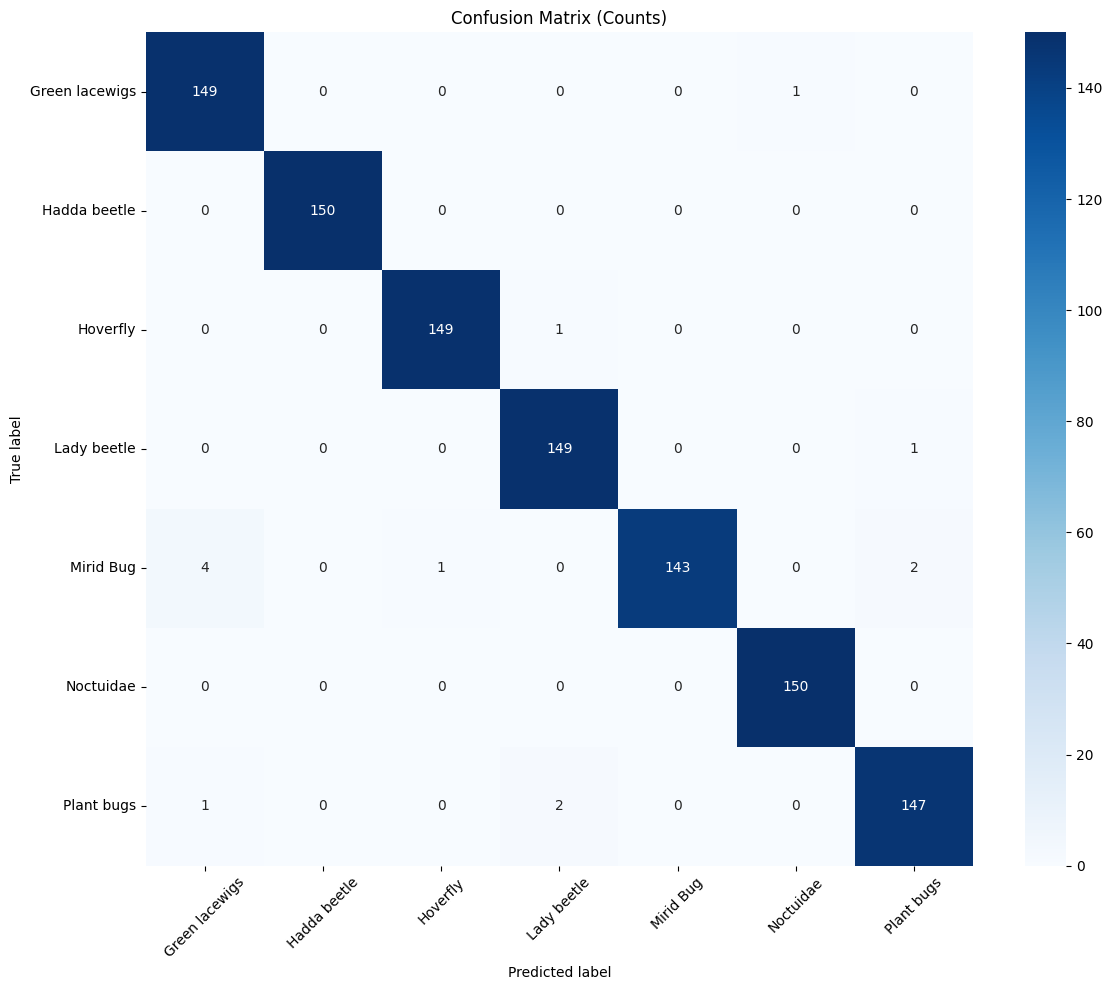

Normalized confusion matrix


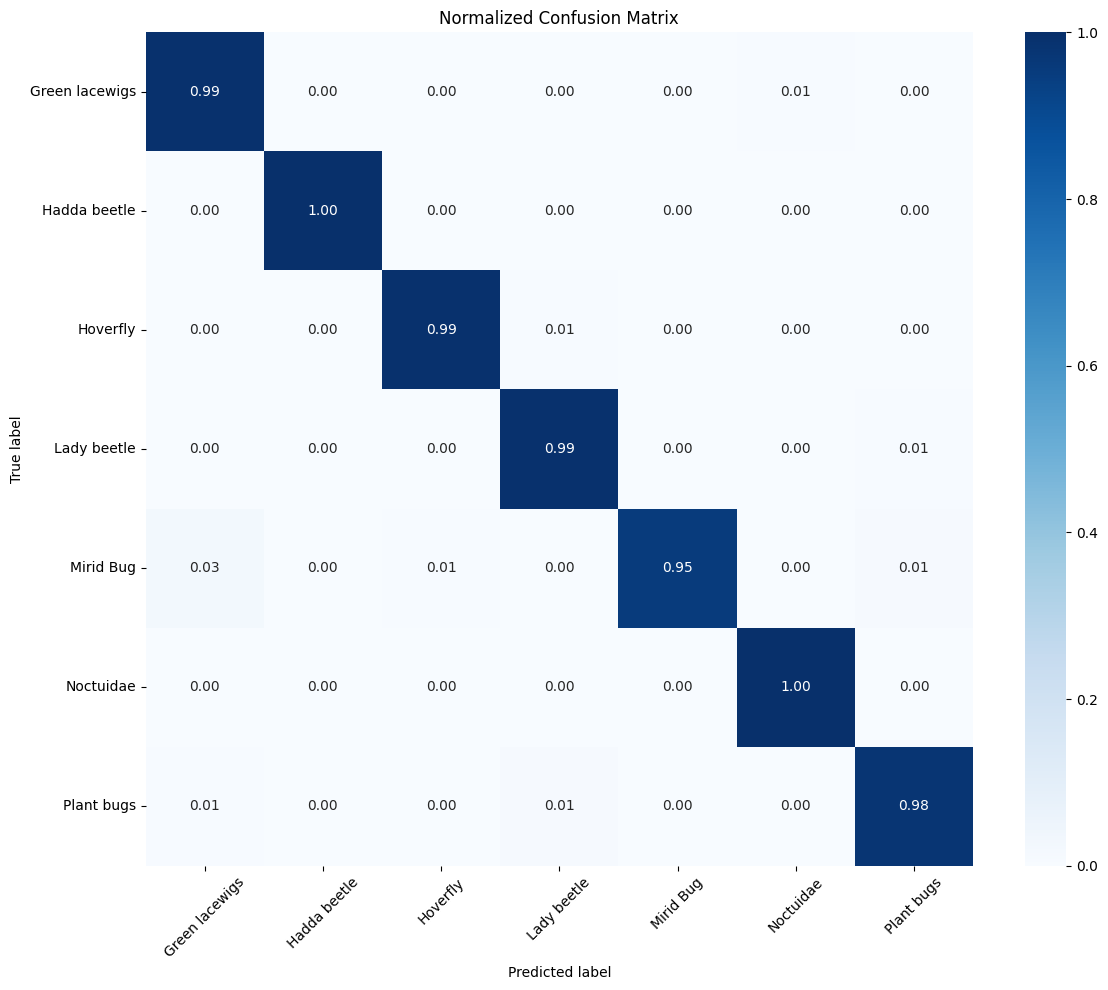

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Get predictions and true labels from test set
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert probabilities to class indices
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds], axis=0)

# 2. Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# 3. Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    cm = confusion_matrix(y_true, y_pred)
    
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd',
                cmap=cmap, xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Plot non-normalized confusion matrix
plot_confusion_matrix(y_true, y_pred_classes, classes=class_names,
                      title='Confusion Matrix (Counts)')

# Plot normalized confusion matrix
plot_confusion_matrix(y_true, y_pred_classes, classes=class_names, normalize=True,
                      title='Normalized Confusion Matrix')

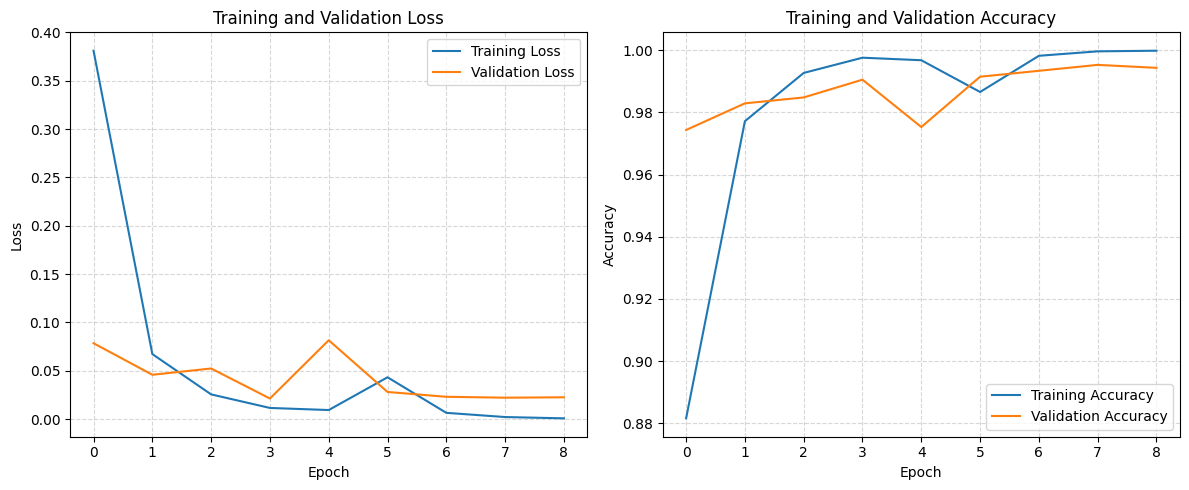


Best Validation Loss: 0.0213 at epoch 4
Corresponding Training Loss: 0.0116
Validation Accuracy at Best Epoch: 0.9905


In [13]:
import matplotlib.pyplot as plt

# Get training history from model.fit()
history = model.history.history

# Create figure with two subplots
plt.figure(figsize=(12, 5))

# 1. Plot Loss Curves
plt.subplot(1, 2, 1)
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 2. Plot Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(history['accuracy'], label='Training Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Optional: Print best validation accuracy
best_val_epoch = np.argmin(history['val_loss'])
print(f"\nBest Validation Loss: {min(history['val_loss']):.4f} at epoch {best_val_epoch + 1}")
print(f"Corresponding Training Loss: {history['loss'][best_val_epoch]:.4f}")
print(f"Validation Accuracy at Best Epoch: {history['val_accuracy'][best_val_epoch]:.4f}")

 9/33 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step

33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step


2025-07-27 18:44:08.276400: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


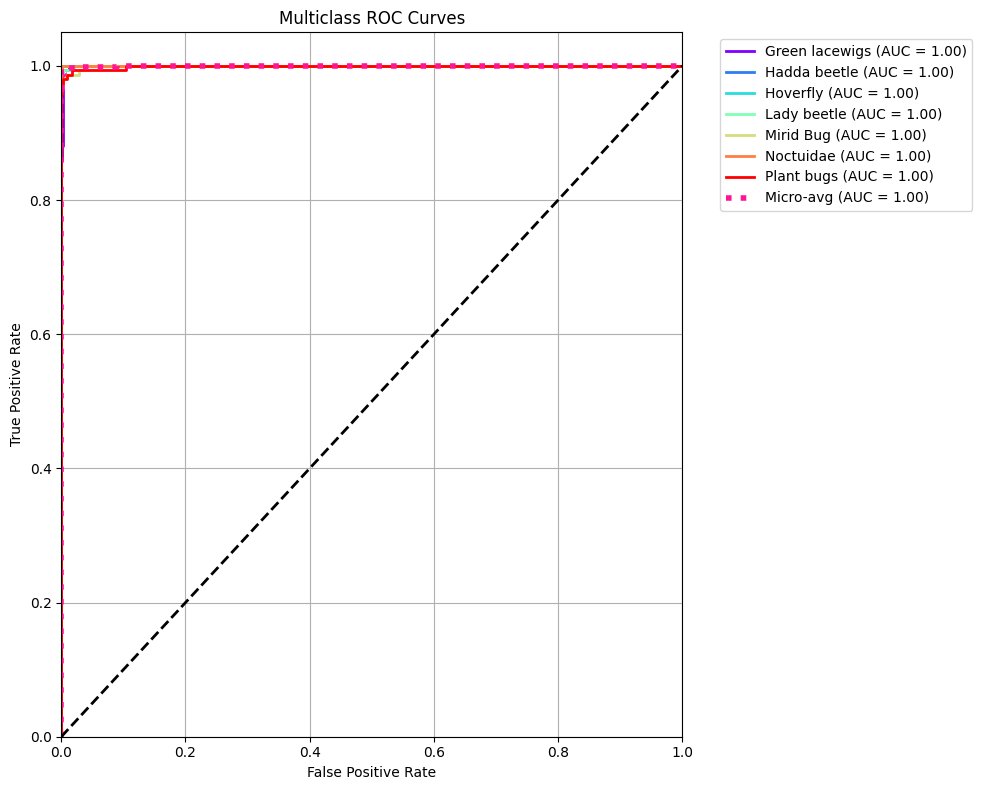


AUC Scores:
Green lacewigs: 0.9996
Hadda beetle: 1.0000
Hoverfly: 1.0000
Lady beetle: 0.9999
Mirid Bug: 0.9995
Noctuidae: 1.0000
Plant bugs: 0.9991

Micro-average AUC: 0.9997


In [14]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

# 1. Get predictions and true labels from test set
y_pred = model.predict(test_ds)
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true_labels = np.argmax(y_true, axis=1)  # Convert one-hot to labels

# 2. Binarize the true labels for multiclass ROC
y_true_bin = label_binarize(y_true_labels, classes=np.arange(NUM_CLASSES))

# 3. Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Compute micro-average ROC curve and area
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# 5. Generate enough colors for all classes
colors = cycle(plt.cm.rainbow(np.linspace(0, 1, NUM_CLASSES)))

# 6. Plot ROC curves
plt.figure(figsize=(10, 8))
for i, color in zip(range(NUM_CLASSES), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='{0} (AUC = {1:0.2f})'.format(class_names[i], roc_auc[i]))

# Plot micro-average curve
plt.plot(fpr["micro"], tpr["micro"],
         label='Micro-avg (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Plot random guessing line
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curves')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Print AUC scores
print("\nAUC Scores:")
for i in range(NUM_CLASSES):
    print(f"{class_names[i]}: {roc_auc[i]:.4f}")
print(f"\nMicro-average AUC: {roc_auc['micro']:.4f}")

 5/33 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step

33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step


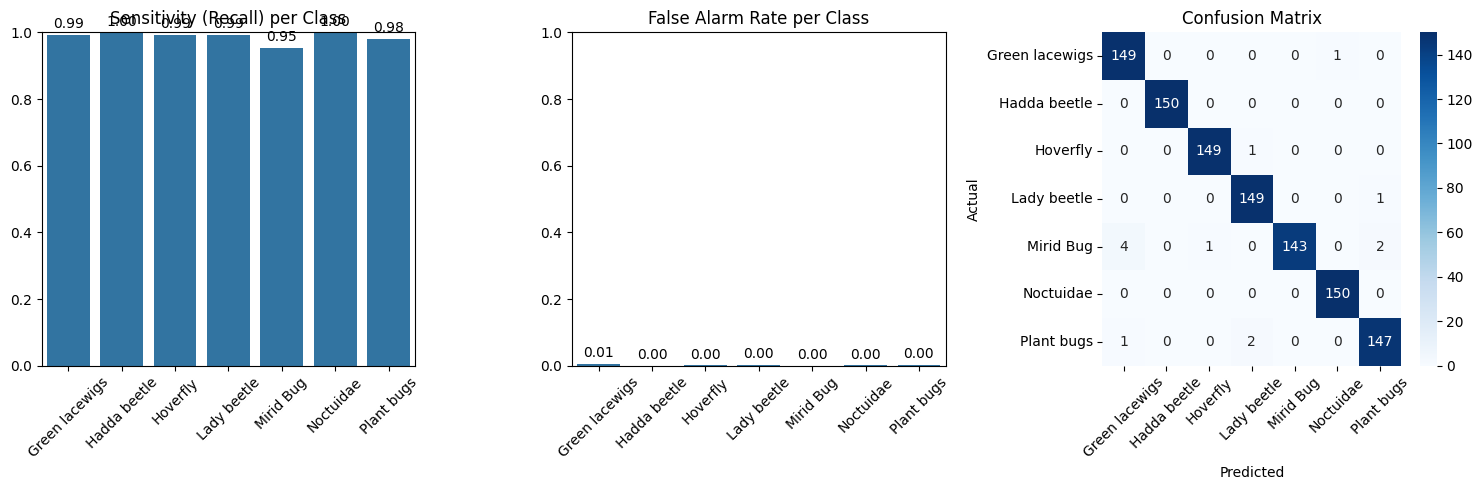


Class-wise Performance Metrics:
Class          Sensitivity    False Alarm Rate    
--------------------------------------------------
Green lacewigs 0.9933         0.0056              
Hadda beetle   1.0000         0.0000              
Hoverfly       0.9933         0.0011              
Lady beetle    0.9933         0.0033              
Mirid Bug      0.9533         0.0000              
Noctuidae      1.0000         0.0011              
Plant bugs     0.9800         0.0033              

Macro-average Sensitivity: 0.9876
Macro-average False Alarm Rate: 0.0021


: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, recall_score

# 1. Get predictions and true labels
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds], axis=0)

# 2. Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# 3. Calculate metrics for each class
sensitivity = []
false_alarm_rate = []
precision = []

for i in range(len(class_names)):
    # Sensitivity (Recall)
    sensitivity.append(recall_score(y_true, y_pred_classes, labels=[i], average=None)[0])
    
    # False Alarm Rate = FP / (FP + TN)
    fp = np.sum(cm[:, i]) - cm[i, i]
    tn = np.sum(cm) - np.sum(cm[i, :]) - np.sum(cm[:, i]) + cm[i, i]
    false_alarm_rate.append(fp / (fp + tn))


# 4. Create visualization
plt.figure(figsize=(15, 5))

# Sensitivity plot
plt.subplot(1, 3, 1)
sns.barplot(x=class_names, y=sensitivity)
plt.title('Sensitivity (Recall) per Class')
plt.ylim(0, 1)
plt.xticks(rotation=45)
for i, v in enumerate(sensitivity):
    plt.text(i, v+0.02, f"{v:.2f}", ha='center')

# False Alarm Rate plot
plt.subplot(1, 3, 2)
sns.barplot(x=class_names, y=false_alarm_rate)
plt.title('False Alarm Rate per Class')
plt.ylim(0, 1)
plt.xticks(rotation=45)
for i, v in enumerate(false_alarm_rate):
    plt.text(i, v+0.02, f"{v:.2f}", ha='center')

# Confusion Matrix
plt.subplot(1, 3, 3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# 5. Print metrics table
print("\nClass-wise Performance Metrics:")
print(f"{'Class':<15}{'Sensitivity':<15}{'False Alarm Rate':<20}")
print("-"*50)
for i in range(len(class_names)):
    print(f"{class_names[i]:<15}{sensitivity[i]:<15.4f}{false_alarm_rate[i]:<20.4f}")


# 6. Calculate macro averages
macro_sensitivity = np.mean(sensitivity)
macro_far = np.mean(false_alarm_rate)
print(f"\nMacro-average Sensitivity: {macro_sensitivity:.4f}")
print(f"Macro-average False Alarm Rate: {macro_far:.4f}")